In [2]:
import pandas as pd

In [4]:
df = pd.read_csv('/content/sample_data/harmful_algae_events.csv')

In [5]:
df.head()

,Event ID,Event Name,Year,Country,Region,Status,Submitter,Created At,Updated At,Event Date,...,Advected Info,Stratification Info,Nutrients,Additional Env Info,Additional Harmful Effect Info,Additional Bloom Info,Management Decision,Economic Losses,References,Contacts
0,14822,NO-26-015,2026,NORWAY,Region 12 (EUR),Submitted,mona.ring.kleiven@hi.no,2026-06-22,2026-06-22,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Harvesting was locally banned. The public was ...,Unknown,NaN,Mona Ring Kleiven
1,14819,NO-26-012,2026,NORWAY,Region 12 (EUR),Submitted,mona.ring.kleiven@hi.no,2026-06-22,2026-06-22,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Harvesting was locally banned. The public was ...,Unknown,NaN,Mona Ring Kleiven
2,14810,NO-26-003,2026,NORWAY,Region 12 (EUR),Submitted,mona.ring.kleiven@hi.no,2026-05-18,2026-05-18,NaN,...,0-3 m,NaN,NaN,NaN,NaN,NaN,Fish farms warned,NaN,NaN,Mona Ring Kleiven
3,14821,NO-26-014,2026,NORWAY,Region 12 (EUR),Submitted,mona.ring.kleiven@hi.no,2026-06-22,2026-06-22,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Harvesting was locally banned. The public was ...,Unknown,NaN,Mona Ring Kleiven
4,14812,NO-26-005,2026,NORWAY,Region 12 (EUR),Submitted,mona.ring.kleiven@hi.no,2026-06-22,2026-06-22,2026-04-06,...,NaN,NaN,NaN,NaN,NaN,NaN,Harvesting was locally banned. The public was ...,Unknown,NaN,Mona Ring Kleiven


In [6]:
df.shape

(4747, 85)

Checking all columns in HAEDAT to understand what data is available



In [7]:
df.columns.tolist()

['Event ID',
 'Event Name',
 'Year',
 'Country',
 'Region',
 'Status',
 'Submitter',
 'Created At',
 'Updated At',
 'Event Date',
 'Start Date',
 'End Date',
 'Date Comments',
 'Quarantine Start',
 'Quarantine End',
 'Additional Date Info',
 'Latitude',
 'Longitude',
 'Location Description',
 'Original Grid Code',
 'Monitoring Grids',
 'Additional Location Info',
 'Monitoring Programme?',
 'Programme Name',
 'Occurred Before?',
 'Occurred Before Details',
 'Water Discoloration',
 'High Phytoplankton',
 'Seafood Toxin',
 'Mass Mortality',
 'Foam/Mucilage',
 'Freshwater',
 'Other Effect',
 'Other Effect Details',
 'Humans Affected',
 'Natural Fish Affected',
 'Aquaculture Fish Affected',
 'Shellfish Affected',
 'Birds Affected',
 'Marine Mammals Affected',
 'Plankton Affected',
 'Benthic Life Affected',
 'Seaweed Affected',
 'Other Terrestrial Affected',
 'Impact Comments',
 'Terrestrial Comments',
 'Toxin Detected?',
 'Toxicity Range',
 'Unexplained Toxicity',
 'Toxicity Comments',
 'Tr

Checking which columns have the most missing values



In [ ]:
print(df.isna().sum().sort_values(ascending=False).head(30))

Checking null counts and dtypes for the columns we could actually use: coordinates, dates, status, and species

In [8]:
key_cols = ["Latitude", "Longitude", "Event Date", "Start Date", "End Date", "Year", "Status", "Causative Species", "Country", "Freshwater", "Advected?",
            "In Situ?", "Toxin Detected?", "Occurred Before?"]
for c in key_cols:
    print(c, "-> nulls:", df[c].isna().sum(), "| dtype:", df[c].dtype)

Latitude -> nulls: 10 | dtype: float64
Longitude -> nulls: 10 | dtype: float64
Event Date -> nulls: 1670 | dtype: object
Start Date -> nulls: 3222 | dtype: object
End Date -> nulls: 3447 | dtype: object
Year -> nulls: 0 | dtype: int64
Status -> nulls: 0 | dtype: object
Causative Species -> nulls: 1857 | dtype: object
Country -> nulls: 0 | dtype: object
Freshwater -> nulls: 0 | dtype: object
Advected? -> nulls: 20 | dtype: object
In Situ? -> nulls: 20 | dtype: object
Toxin Detected? -> nulls: 0 | dtype: object
Occurred Before? -> nulls: 17 | dtype: object


In [9]:
print(df["Status"].value_counts())
print()
print(df["Freshwater"].value_counts())
print()

Status
Approved     4730
Submitted      17
Name: count, dtype: int64

Freshwater
No     4728
Yes      19
Name: count, dtype: int64



In [10]:
date_cols = ["Event Date", "Start Date", "End Date"]
has_any_date = df[date_cols].notna().any(axis=1)
print("rows with at least one date field:", has_any_date.sum())
print("rows with zero date info:", (~has_any_date).sum())

rows with at least one date field: 4038
rows with zero date info: 709


In [11]:
valid_coords = (
    df["Latitude"].notna() & df["Longitude"].notna()
    & df["Latitude"].between(-90, 90)
    & df["Longitude"].between(-180, 180)
)
has_date = df[["Event Date", "Start Date"]].notna().any(axis=1)
not_freshwater = df["Freshwater"] == "No"
approved = df["Status"] == "Approved"

usable_mask = valid_coords & has_date & not_freshwater & approved
print("Final usable events:", usable_mask.sum())
print("Dropped:", len(df) - usable_mask.sum())

Final usable events: 3998
Dropped: 749


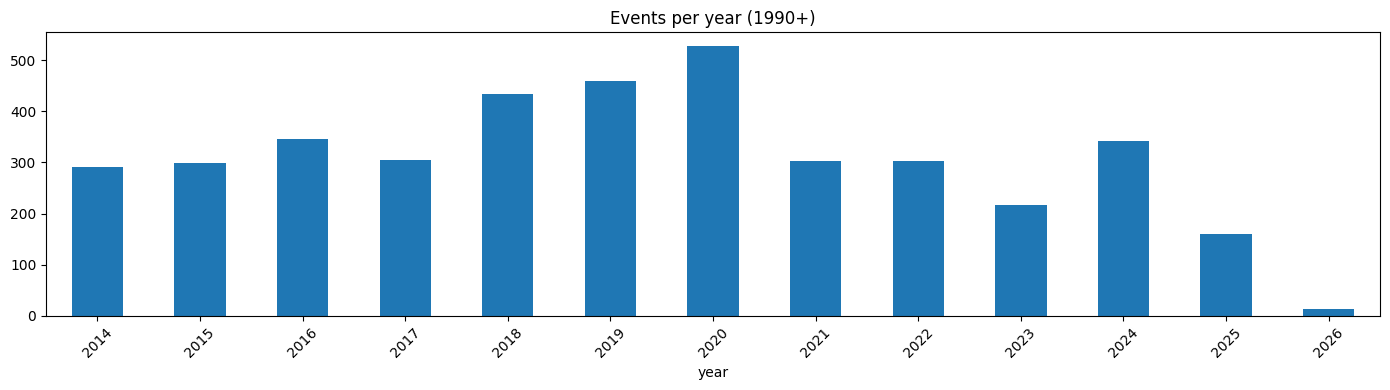

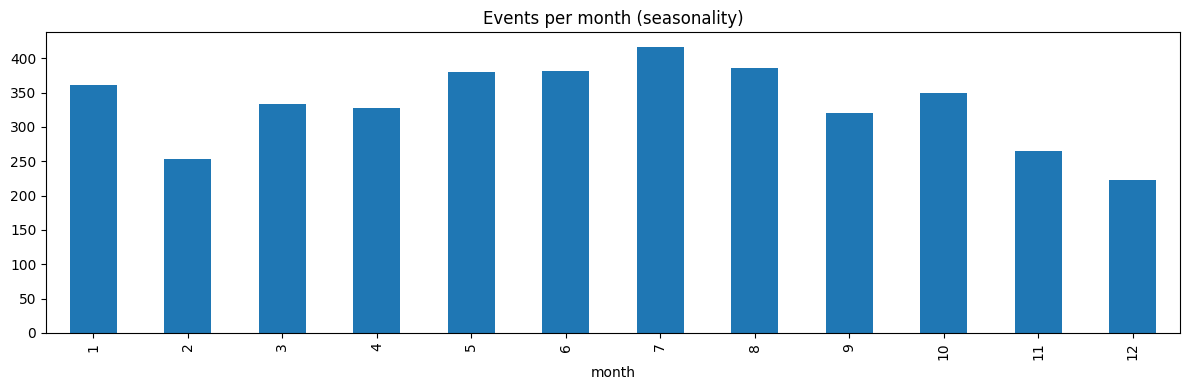

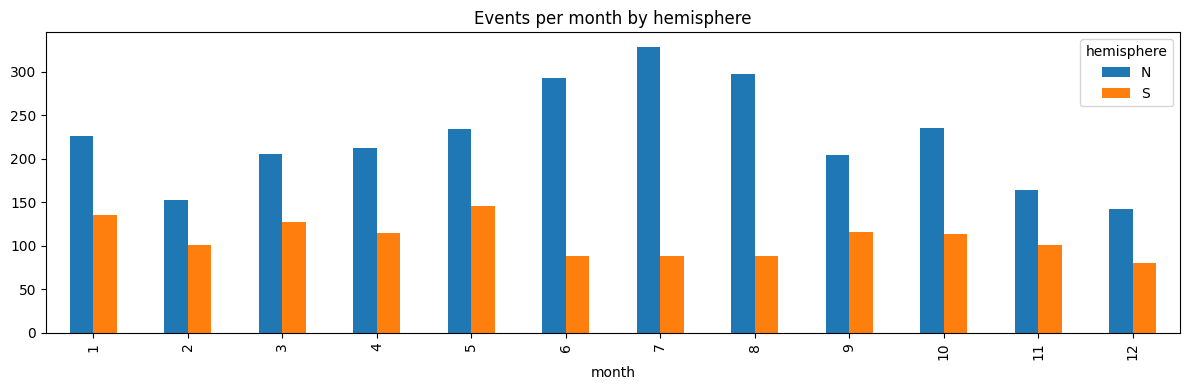

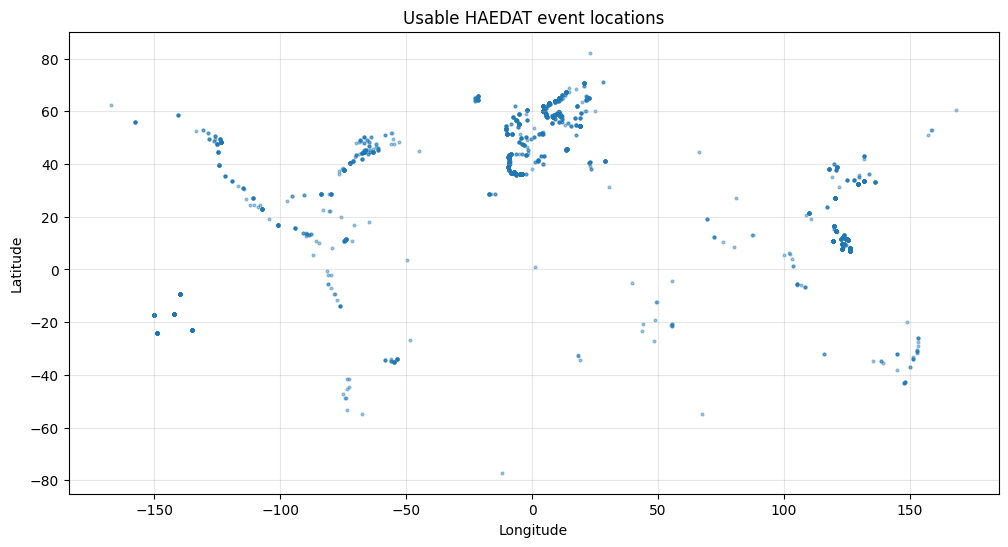

In [12]:
usable = df[usable_mask].copy()

# coalesced date for plotting: Event Date first, fallback to Start Date
usable["best_date"] = pd.to_datetime(usable["Event Date"].fillna(usable["Start Date"]))
usable["year"] = usable["best_date"].dt.year
usable["month"] = usable["best_date"].dt.month

import matplotlib.pyplot as plt

# Events per year, 1990+ only
usable_recent = usable[usable["year"] >= 1990]

fig, ax = plt.subplots(figsize=(14, 4))
usable_recent["year"].value_counts().sort_index().plot(kind="bar", ax=ax, title="Events per year (1990+)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Events per month (seasonality, global)
fig, ax = plt.subplots(figsize=(12, 4))
usable["month"].value_counts().sort_index().plot(kind="bar", ax=ax, title="Events per month (seasonality)")
plt.tight_layout()
plt.show()

# Events per month, split by hemisphere
usable["hemisphere"] = usable["Latitude"].apply(lambda x: "N" if x >= 0 else "S")
usable.groupby(["hemisphere", "month"]).size().unstack(0).plot(kind="bar", figsize=(12, 4), title="Events per month by hemisphere")
plt.tight_layout()
plt.show()

# Geographic distribution
plt.figure(figsize=(12, 6))
plt.scatter(usable["Longitude"], usable["Latitude"], s=4, alpha=0.4)
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.title("Usable HAEDAT event locations")
plt.grid(alpha=0.3)
plt.show()

In [13]:
print("no coords:", (~valid_coords).sum())
print("no Event/Start date:", (~has_date).sum())
print("  of those, have End Date:", (~has_date & df["End Date"].notna()).sum())
print("Freshwater blank:", df["Freshwater"].isna().sum())
print("not approved:", (~approved).sum())

no coords: 13
no Event/Start date: 715
  of those, have End Date: 6
Freshwater blank: 0
not approved: 17
